<a href="https://colab.research.google.com/github/AboimovVlad/poltava-AR/blob/main/Docs/ML_trning/YOLO_train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics

import zipfile
import os
import yaml

zip_path = '/content/Sculpture.v1i.yolov82.zip'
extract_path = '/content/monuments_dataset'

if not os.path.exists(zip_path):
    raise FileNotFoundError("Файл /content/Sculpture.v1i.yolov82.zip не найден!")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

actual_yaml_path = None
for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(('.yaml', '.yml')):
            actual_yaml_path = os.path.join(root, file)
            break

if not actual_yaml_path:
    raise FileNotFoundError("Файл data.yaml не найден в архиве!")

project_folder = os.path.dirname(actual_yaml_path)

with open(actual_yaml_path, 'r') as f:
    config = yaml.safe_load(f)

config['path'] = project_folder
config['train'] = 'train/images'
config['val'] = 'train/images'
config['test'] = ''
config['names'] = {0: 'monument'}

with open(actual_yaml_path, 'w') as f:
    yaml.dump(config, f)

print("Готово! YAML настроен по пути:", actual_yaml_path)


Готово! YAML настроен по пути: /content/monuments_dataset/Sculpture.v1i.yolov8/data.yaml


In [ ]:
from ultralytics import YOLO
import os

model = YOLO('yolo11n.pt')

results = model.train(
    data=actual_yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    val=True,
    fraction=0.8
)

# Автоматически запоминаем точный путь к best.pt (train, train2, train3 и т.д.)
best_weights_path = os.path.join(str(results.save_dir), 'weights', 'best.pt')
print("Обучение завершено! Лучшие веса сохранены здесь:", best_weights_path)



Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/monuments_dataset/Sculpture.v1i.yolov8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format


image 1/1 /content/photo_2026-11-13_12-30-14.jpg: 640x288 (no detections), 9.8ms
Speed: 1.9ms preprocess, 9.8ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 288)


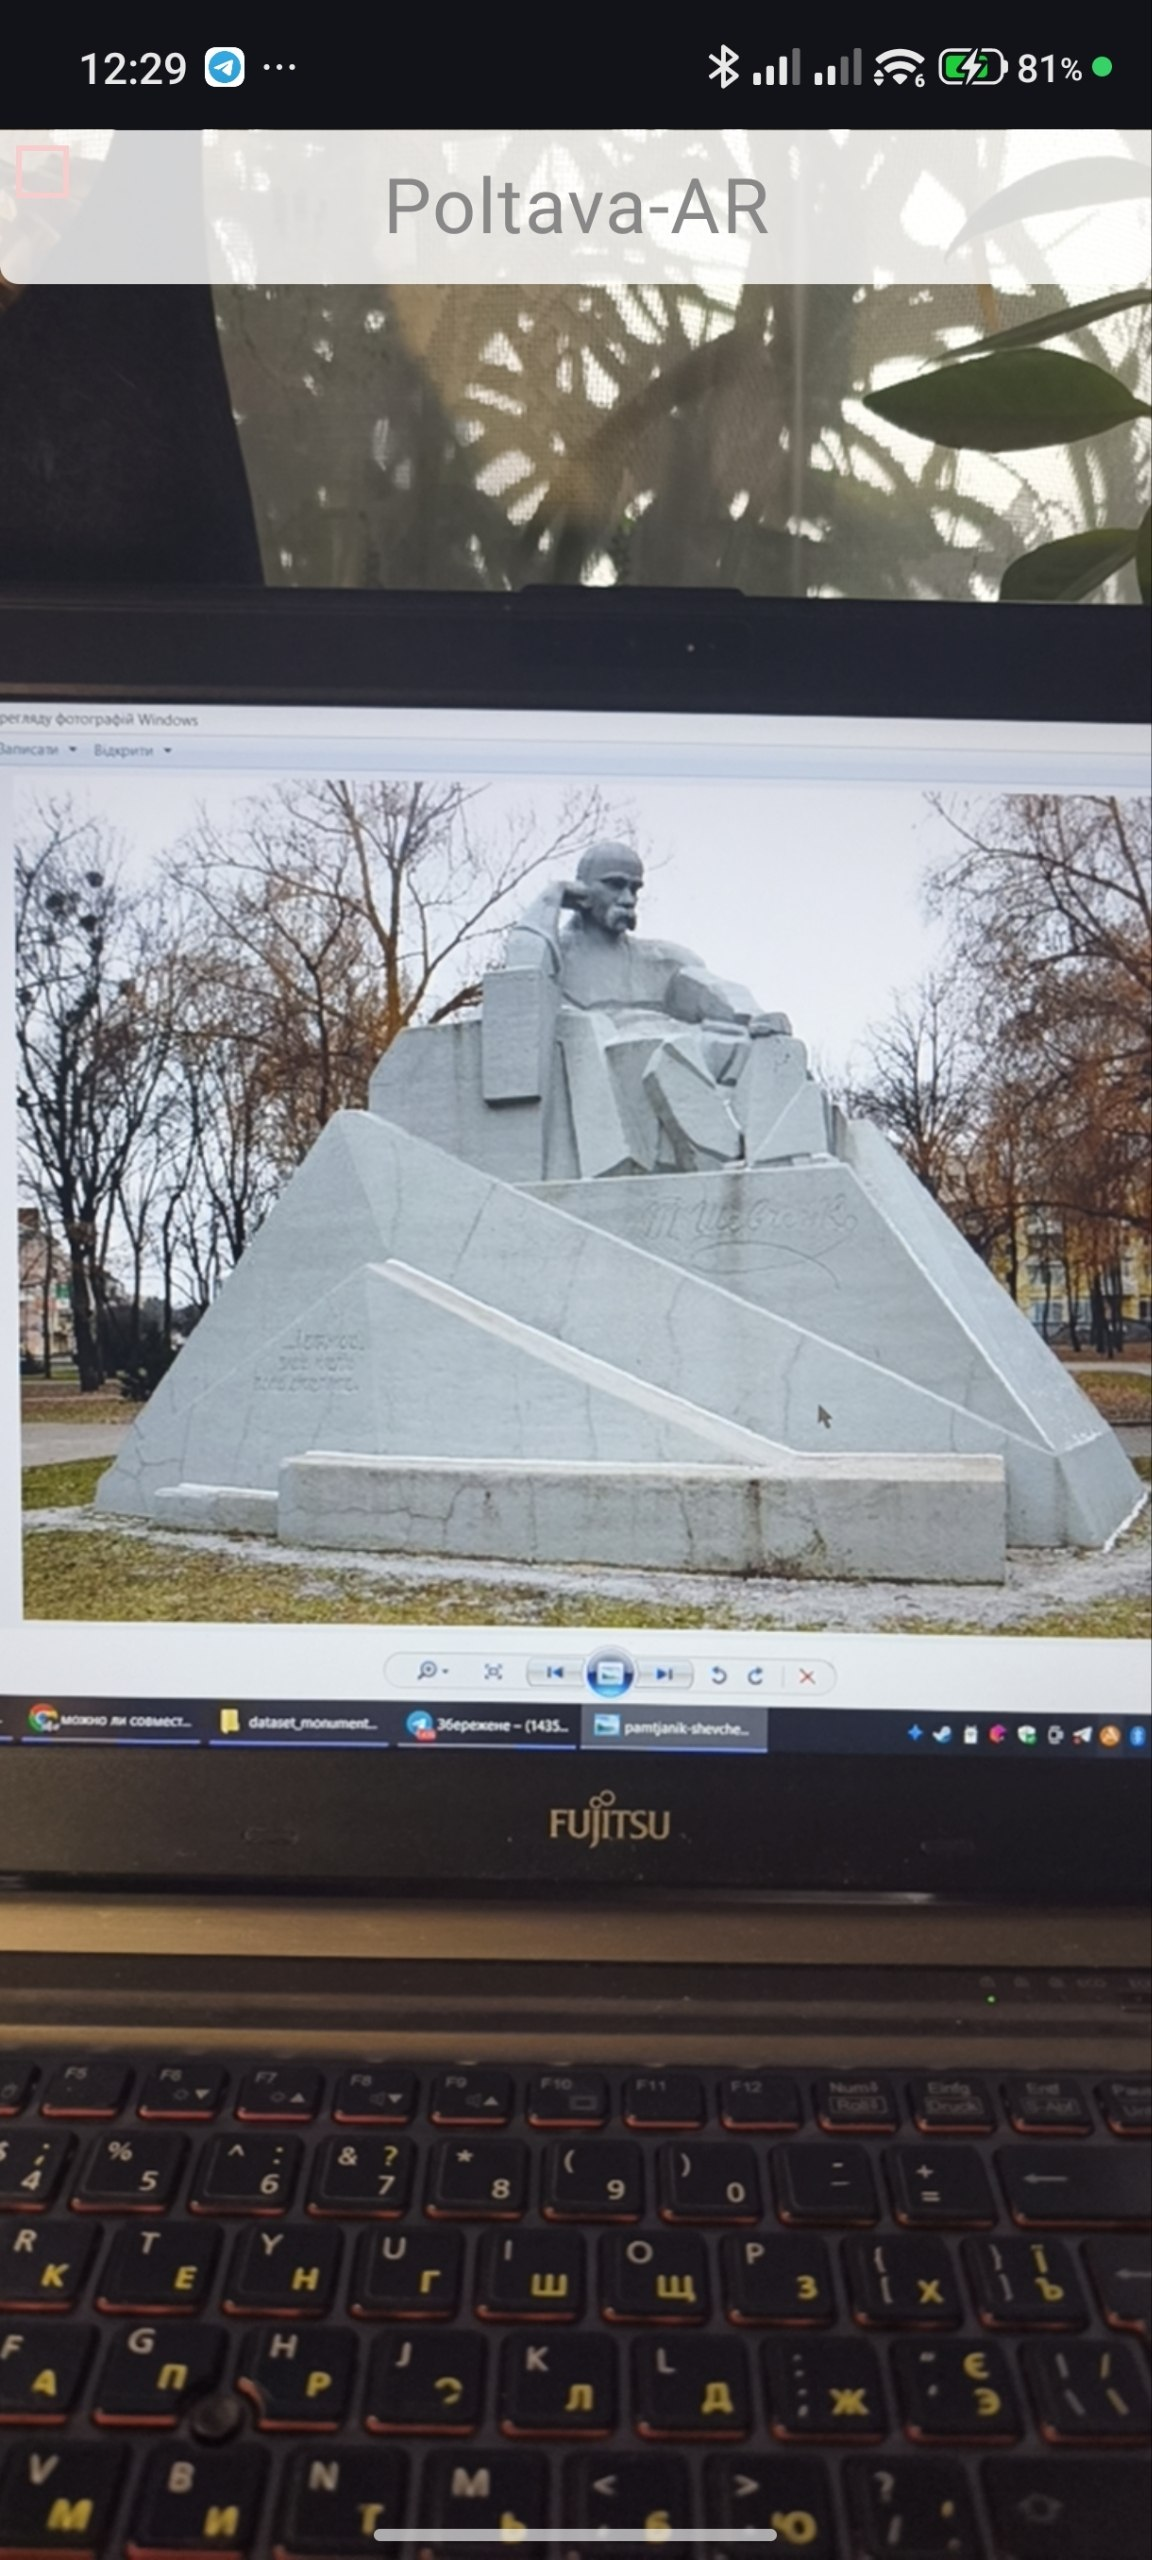

In [ ]:
from ultralytics import YOLO
import cv2
from google.colab.patches import cv2_imshow

# 1. Загружаем обученные веса
my_model = YOLO('/content/runs/detect/train/weights/best.pt')

# 2. Делаем предсказание
results = my_model.predict(source='/content/photo_2026-11-13_12-30-14.jpg', conf=0.4)

# 3. Берем ПЕРВЫЙ элемент из списка результатов и рисуем рамку
res_plotted = results[0].plot()

# 4. Выводим картинку на экран
cv2_imshow(res_plotted)


In [ ]:
!pip install -q onnx onnx2tf sng4onnx onnx_graphsurgeon tensorflow

from ultralytics import YOLO
from google.colab import files
import shutil
import os

# Загружаем обученные веса из Блока 2
trained_model = YOLO(best_weights_path)

# Экспортируем в TFLite (при установленном onnx2tf Ultralytics соберет правильный NHWC граф)
exported_file = trained_model.export(format='tflite', imgsz=640)

# Копируем итоговый файл с простым именем best.tflite и скачиваем
final_tflite = '/content/best.tflite'
shutil.copy(str(exported_file), final_tflite)

print("Готово! Скачиваем файл:", final_tflite)
files.download(final_tflite)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.35.1 which is incompatible.
WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)
requir

/usr/local/lib/python3.13/dist-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.
W1113 12:02:46.682000 400 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.



LiteRT: starting export with litert_torch 0.10.0...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

(00:02) [START] LiteRT-Torch Convert > Torch Export: serving_default > ExportedProgram Run Decompositions

... (20 outputs left out)

(00:00) [ DONE] Write Model to /content/runs/detect/train/weights/best.tflite (+00:00)

LiteRT: export success ✅ 26.7s, saved as '/content/runs/detect/train/weights/best.tflite' (10.2 MB)

Export complete (27.0s)
Results saved to /content/runs/detect/train/weights/best.tflite
Predict:         yolo predict task=detect model=/content/runs/detect/train/weights/best.tflite imgsz=640 
Validate:        yolo val task=detect model=/content/runs/detect/train/weights/best.tflite imgsz=640 data=/content/monuments_dataset/Sculpture.v1i.yolov8/data.yaml 
Visualize:       https://netron.app
Готово! Скачиваем файл: /content/best.tflite


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>